# AgriOptima: Soil anomaly detection

Isolation Forest flags unusual soil patterns. Without confirmed anomaly labels, we cannot report classification accuracy. A flag requests human review; it does not prove a measurement is wrong.

Run each cell in order. This notebook trains its own evaluation model and does not overwrite application artifacts.

## 1. Import libraries and find the project
Pandas reads tables; NumPy handles numbers; Matplotlib draws figures.

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

# Works when Jupyter starts in the project root or this notebook folder.
ROOT = Path.cwd()
if not (ROOT / 'DataSets').exists():
    ROOT = ROOT.parent
assert (ROOT / 'DataSets').exists(), 'Open Jupyter in the project folder.'

## 2. Read, inspect and clean raw data
The source CSVs remain unchanged. Invalid rows and duplicate handling are visible below. Earlier audit records are preserved in the recovery copy outside this project.

In [2]:
features = ['depth_top_cm', 'depth_bottom_cm', 'ph_h2o', 'organic_carbon_g_kg',
            'total_nitrogen_g_kg', 'sand_pct', 'silt_pct', 'clay_pct',
            'bulk_density_g_cm3', 'cec_cmol_kg', 'coarse_fragments_vol_pct']
location = ['latitude', 'longitude']
samples = []
# Read one depth file at a time. Sample equally so every depth is represented.
for path in sorted((ROOT / 'DataSets/Soil Grid').glob('soilgrids_*.csv')):
    frame = pd.read_csv(path)
    for column in features + location:
        frame[column] = pd.to_numeric(frame[column], errors='coerce')
    valid = np.isfinite(frame[features + location]).all(axis=1)
    frame = frame.loc[valid]
    sample = frame.sample(min(5000, len(frame)), random_state=42).copy()
    sample['source_depth_file'] = path.name
    samples.append(sample)
data = pd.concat(samples, ignore_index=True)
data = data.drop_duplicates(subset=location + ['depth_top_cm', 'depth_bottom_cm'])
print('Prepared soil rows:', len(data))
display(data.head())

Prepared soil rows: 30000


,latitude,longitude,depth_top_cm,depth_bottom_cm,ph_h2o,organic_carbon_g_kg,total_nitrogen_g_kg,sand_pct,silt_pct,clay_pct,bulk_density_g_cm3,cec_cmol_kg,coarse_fragments_vol_pct,source_depth_file
0,29.228952,76.748659,0,5,8.8,11.2,1.25,36.1,33.7,30.3,1.42,13.7,7.5,soilgrids_0-5cm.csv
1,32.536305,75.356020,0,5,6.4,47.1,3.77,34.8,40.5,24.7,1.31,20.8,10.4,soilgrids_0-5cm.csv
2,30.853952,77.218901,0,5,6.0,46.2,4.68,38.6,37.6,23.7,1.18,21.0,20.8,soilgrids_0-5cm.csv
3,27.632629,77.454022,0,5,8.2,7.8,1.22,41.1,31.8,27.1,1.46,13.6,6.8,soilgrids_0-5cm.csv
4,29.286305,77.038039,0,5,8.7,10.7,1.15,38.9,34.4,26.7,1.42,13.9,5.5,soilgrids_0-5cm.csv


### Look at the data
This overview describes the dataset. It is not a prediction result.

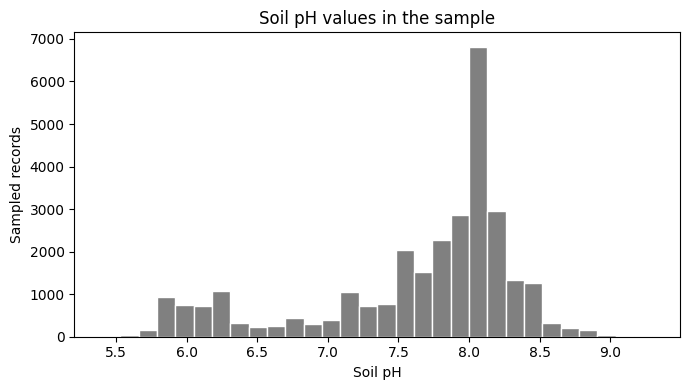

In [3]:
data['ph_h2o'].plot.hist(bins=30, figsize=(7, 4), color='gray', edgecolor='white')
plt.xlabel('Soil pH')
plt.ylabel('Sampled records')
plt.title('Soil pH values in the sample')
plt.tight_layout()
plt.show()

This shows common and less common pH ranges in the sample. An uncommon pH alone does not prove an error; the anomaly model considers several properties together.

## 3. Prepare inputs, split data, train and evaluate
X contains measurements; y contains known answers in supervised tasks. Fit preprocessing on training rows only. Keep time order for prices/yield and keep soil locations together.

In [4]:

from pathlib import Path
import pandas as pd
from sklearn.model_selection import GroupShuffleSplit
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.ensemble import IsolationForest

In [5]:
features = [
    "depth_top_cm",
    "depth_bottom_cm",
    "ph_h2o",
    "organic_carbon_g_kg",
    "total_nitrogen_g_kg",
    "sand_pct",
    "silt_pct",
    "clay_pct",
    "bulk_density_g_cm3",
    "cec_cmol_kg",
    "coarse_fragments_vol_pct",
]

In [6]:
# 2. Keep locations together so the same location cannot appear on both sides.
groups = (
    data["latitude"].round(5).astype(str) + "|" + data["longitude"].round(5).astype(str)
)
splitter = GroupShuffleSplit(n_splits=1, test_size=0.20, random_state=42)
train_indices, test_indices = next(splitter.split(data, groups=groups))
train = data.iloc[train_indices]
test = data.iloc[test_indices]

In [7]:
# 3. Isolation Forest learns which patterns are unusual.
# contamination=0.02 sets a training threshold; it is not measured accuracy.
model = Pipeline(
    [
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler()),
        (
            "detector",
            IsolationForest(
                contamination=0.02, n_estimators=200, random_state=42, n_jobs=1
            ),
        ),
    ]
)
model.fit(train[features])

Pipeline(steps=[('imputer', SimpleImputer(strategy='median')),
                ('scaler', StandardScaler()),
                ('detector',
                 IsolationForest(contamination=0.02, n_estimators=200, n_jobs=1,
                                 random_state=42))])

In [8]:
# 4. -1 means review candidate; +1 means not flagged by this model.
predictions = model.predict(test[features])
flagged = predictions == -1
scores = model.decision_function(test[features])
print("Test records:", len(test))
print("Records to review:", flagged.sum())
print("Flagged percentage:", flagged.mean() * 100)
print("First five anomaly scores:", scores[:5])
# Without confirmed anomaly labels, do not claim accuracy or that every flag is an error.

Test records: 6000
Records to review: 160
Flagged percentage: 2.666666666666667
First five anomaly scores: [0.21224918 0.09502345 0.14061865 0.1192759  0.19296177]


## 4. Figures and interpretation
These figures use held-out predictions when labels exist. For soil, they describe the held-out groups or scores.

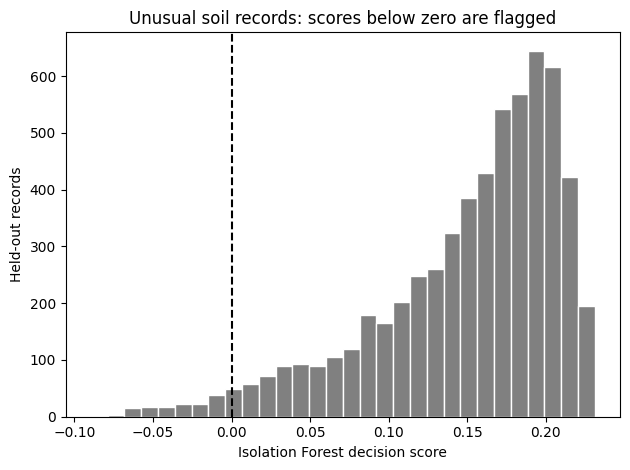

,depth_top_cm,depth_bottom_cm,ph_h2o,organic_carbon_g_kg,total_nitrogen_g_kg,sand_pct,silt_pct,clay_pct,bulk_density_g_cm3,cec_cmol_kg,coarse_fragments_vol_pct
62,0,5,5.7,62.9,6.41,41.7,33.5,24.7,1.12,22.9,15.9
302,0,5,7.1,70.9,4.52,44.4,37.3,18.3,1.07,29.9,31.8
309,0,5,5.6,83.2,7.73,40.7,34.2,25.0,1.13,24.1,14.2
339,0,5,6.5,87.5,5.52,40.8,37.3,21.9,1.10,29.1,18.4
349,0,5,6.7,59.8,5.11,44.0,37.6,18.4,1.09,34.2,34.5


In [9]:
plt.hist(scores, bins=30, color='gray', edgecolor='white')
plt.axvline(0, color='black', linestyle='--')
plt.xlabel('Isolation Forest decision score')
plt.ylabel('Held-out records')
plt.title('Unusual soil records: scores below zero are flagged')
plt.tight_layout()
plt.show()
display(test.loc[flagged, features].head())

Scores below zero are review candidates. The table shows example flagged records. The threshold is not an observed error rate.

## 5. Save this learning model separately
The working application models remain unchanged. The saved bundle includes the features and preprocessing needed for later use. This is the holdout experiment model, not an all-data production refit.

In [10]:
import joblib
output = ROOT / 'saved_models'
output.mkdir(exist_ok=True)
bundle = {'model': model, 'features': features}
joblib.dump(bundle, output / '06_soil_anomalies.joblib')
print('Learning artifact saved separately.')

Learning artifact saved separately.


## 6. Viva summary and limitations
Isolation Forest flags unusual soil patterns. Without confirmed anomaly labels, we cannot report classification accuracy. A flag requests human review; it does not prove a measurement is wrong.

Explain: source and target, cleaning choices, split, preprocessing, algorithm, metric, baseline (if applicable), and one limitation. Fitted preprocessing must also be used for new requests. No custom Python functions or classes are defined in this notebook.